Water qulaity prediction

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report,confusion_matrix

In [3]:
df = pd.read_csv("water_quality_dataset1.csv")
print("Dataset Shape:",df.shape)
# to check mising values
print(df.isnull().sum())

Dataset Shape: (100800, 5)
pH               0
TDS_ppm          0
Turbidity_NTU    0
Temperature_C    0
Label            0
dtype: int64


In [4]:
df.columns

Index(['pH', 'TDS_ppm', 'Turbidity_NTU', 'Temperature_C', 'Label'], dtype='object')

In [18]:
df

,pH,TDS_ppm,Turbidity_NTU,Temperature_C,Label
0,7.38,138.7,0.25,20.25,Safe
1,7.42,79.2,0.45,20.14,Safe
2,7.05,104.1,1.18,20.12,Safe
3,7.32,112.8,0.53,19.65,Safe
4,6.87,171.9,1.97,19.42,Safe
...,...,...,...,...,...
100795,7.85,1150.7,28.62,25.84,Unsafe
100796,8.28,993.4,25.85,26.00,Unsafe
100797,8.09,1105.9,25.40,26.86,Unsafe
100798,8.16,1060.5,28.47,26.62,Unsafe


In [6]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100800 entries, 0 to 100799
Data columns (total 5 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   pH             100800 non-null  float64
 1   TDS_ppm        100800 non-null  float64
 2   Turbidity_NTU  100800 non-null  float64
 3   Temperature_C  100800 non-null  float64
 4   Label          100800 non-null  object 
dtypes: float64(4), object(1)
memory usage: 3.8+ MB


,pH,TDS_ppm,Turbidity_NTU,Temperature_C
count,100800.000000,100800.000000,100800.000000,100800.000000
mean,7.593915,692.646992,11.306750,24.883516
std,0.799464,647.331906,9.868407,2.688138
min,6.090000,28.600000,0.000000,16.560000
25%,7.010000,163.000000,1.920000,23.090000
50%,7.380000,472.850000,9.970000,25.040000
75%,8.100000,1023.325000,18.540000,26.930000
max,9.960000,2806.100000,72.750000,31.510000


In [7]:
# check duplicates
print("Total duplicate rows:", df.duplicated().sum())

Total duplicate rows: 0


Label
Unsafe    70560
Safe      30240
Name: count, dtype: int64


<Axes: title={'center': 'Water Safety Distribution'}, xlabel='Water Quality', ylabel='Count'>

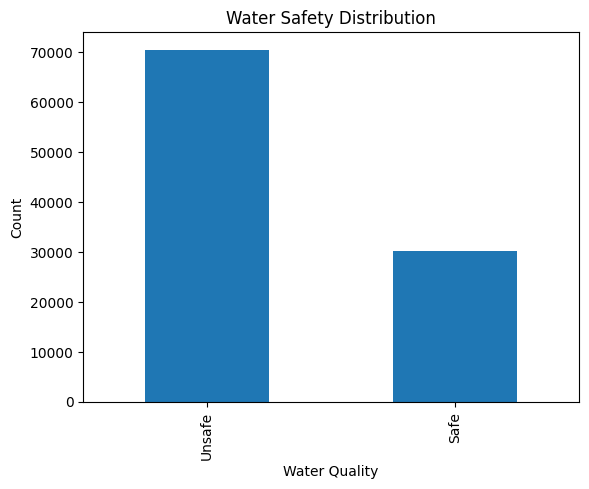

In [8]:
#counts the number of records in each category
print(df["Label"].value_counts()) 
df["Label"].value_counts().plot(
    kind="bar",
    title="Water Safety Distribution",
    xlabel="Water Quality",
    ylabel="Count"
)

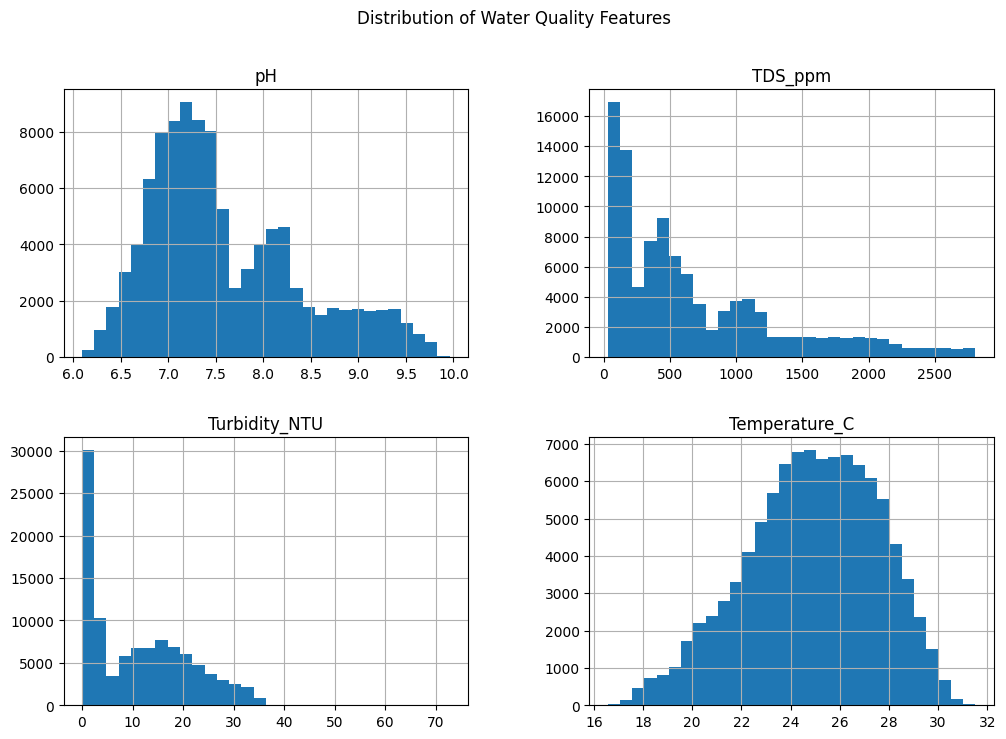

In [9]:
df.hist(figsize=(12, 8), bins=30)
plt.suptitle("Distribution of Water Quality Features")
plt.show()

In [10]:
X = df[["pH", "TDS_ppm", "Turbidity_NTU", "Temperature_C"]]
y = df["Label"]
print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

Input Features Shape: (100800, 4)
Target Shape: (100800,)


In [11]:
from sklearn.preprocessing import LabelEncoder
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)
print("Encoded Labels:")
print(label_encoder.classes_)

Encoded Labels:
['Safe' 'Unsafe']


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (80640, 4)
Testing Data: (20160, 4)


In [13]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [14]:
lr_model = LogisticRegression()
lr_model.fit(X_train_scaled, y_train)
y_pred_lr = lr_model.predict(X_test_scaled)
print("Logistic Regression Accuracy:",
      accuracy_score(y_test, y_pred_lr))
# Confusion Matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))
print("\nClassification report:")
print(classification_report(y_test,y_pred_lr))

Logistic Regression Accuracy: 0.9999007936507937

Confusion Matrix:
[[ 6048     0]
 [    2 14110]]

Classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      6048
           1       1.00      1.00      1.00     14112

    accuracy                           1.00     20160
   macro avg       1.00      1.00      1.00     20160
weighted avg       1.00      1.00      1.00     20160



In [17]:
new_water = pd.DataFrame({
    "pH": [7.2],
    "TDS_ppm": [250],
    "Turbidity_NTU": [2.0],
    "Temperature_C": [25]
})

lr_prediction = lr_model.predict(
    scaler.transform(new_water)
)
# converts it back 
#lr_result = label_encoder.inverse_transform(lr_prediction)

print("Logistic Regression Prediction:", lr_prediction)

Logistic Regression Prediction: [0]
